# Step 8a: Feature 1, AOV (average order value)

**Goal:** add ONE feature to the ratio Tweedie model (7e) and measure its effect, then use what we see to decide the keep rule. (We had proposed "keep if R² improves in at least 9 of 10 fold splits"; you found that strict, so we look at real evidence first.)

**Test design (unchanged):** the 7e settings are kept FIXED (no re-tuning), and both models (R, F, M vs R, F, M + AOV) are scored on the SAME 10 fold splits, so the differences are paired.

**AOV** = gross purchase spend ÷ number of purchase invoices (the size of an *order*, not net of returns). Code: `src/step8_features.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binom, norm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from metrics import r2
from step3_split import load_ledger, make_snapshot, TRAIN_CUTOFF
from step7b_xgboost import oof_with_seed
from step7e_ratio import RatioXGB, suggest_ratio
from step8_features import build_features, screen
from tuning import tune

pd.set_option("display.width", 200)
train = make_snapshot(load_ledger(), TRAIN_CUTOFF)
y = train.target; ya = y.to_numpy()
X_base = build_features(train)
X_new = build_features(train, ("AOV",))
X_new.head()

/data/home/mitanshub/miniconda3/envs/ml_clv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Recency,Frequency,Monetary,AOV
Customer ID,,,,
12346,156,2,169.36,84.68
12347,31,1,611.53,611.53
12348,65,1,222.16,222.16
12349,34,3,2646.99,890.38
12351,2,1,300.93,300.93


## 1. What AOV looks like

,count,mean,std,min,25%,50%,75%,max
AOV (£ per order),4242.0,378.6,474.1,1.6,181.8,290.8,425.9,11880.8


Spearman correlation of AOV with the other features: {'Recency': np.float64(-0.15), 'Frequency': np.float64(0.19), 'Monetary': np.float64(0.68)}


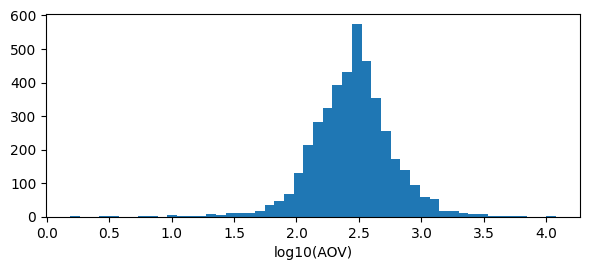

In [2]:
display(X_new["AOV"].describe().round(1).to_frame("AOV (£ per order)").T)
print("Spearman correlation of AOV with the other features:", {c: round(X_new["AOV"].corr(X_new[c], method="spearman"), 2) for c in ("Recency", "Frequency", "Monetary")})
fig, ax = plt.subplots(figsize=(6, 2.8)); ax.hist(np.log10(X_new["AOV"]), bins=50); ax.set_xlabel("log10(AOV)"); plt.tight_layout()

AOV is strongly tied to Monetary (rank correlation 0.68; Monetary ≈ AOV × Frequency), so most of it is already known to the model.

## 2. Does AOV carry any information about the multiplier?

The ratio model predicts the multiplier (future spend ÷ past spend). Rank correlation of each feature with the REAL multiplier among customers who bought:

In [3]:
scale = X_base["Monetary"].clip(lower=50).to_numpy(); buys = ya > 0
mult = ya[buys] / scale[buys]
pd.Series({c: pd.Series(X_new[c].to_numpy()[buys]).corr(pd.Series(mult), method="spearman") for c in ("Recency", "Frequency", "Monetary", "AOV")}).round(3).to_frame("Spearman with real multiplier")

,Spearman with real multiplier
Recency,0.203
Frequency,-0.455
Monetary,-0.453
AOV,-0.197


AOV does carry some signal (-0.20, about the size of Recency's +0.20), but it overlaps with Monetary (-0.45) and Frequency (-0.46), which the model already has. So it is information the model mostly has.

## 3. The paired screen: 10 fold splits, settings fixed

In [4]:
t = screen(X_base, X_new, y)
display(t.round(3))
summ = {}
for col, label in (("R2 diff", "R2 (new - base)"), ("MAE gain", "MAE gain in £ (base - new)"), ("Cap diff", "Capture@20% (new - base)")):
    d = t[col]
    summ[label] = {"mean": d.mean(), "sd across splits": d.std(), "splits improved": f"{(d > 0).sum()}/10",
                   "paired t (mean / (sd/sqrt(10)))": d.mean() / (d.std() / np.sqrt(len(d)))}
display(pd.DataFrame(summ).T)

,R2 base,R2 new,R2 diff,MAE base,MAE new,MAE gain,Cap base,Cap new,Cap diff
seed,,,,,,,,,
0,0.756,0.730,-0.026,509.075,515.066,-5.991,0.742,0.742,0.000
1,0.729,0.698,-0.032,516.858,521.125,-4.267,0.742,0.743,0.002
2,0.731,0.689,-0.042,514.143,517.503,-3.360,0.744,0.743,-0.000
3,0.725,0.701,-0.024,518.187,518.608,-0.421,0.743,0.742,-0.001
4,0.738,0.705,-0.032,514.841,519.385,-4.544,0.744,0.742,-0.002
5,0.748,0.722,-0.027,511.139,514.925,-3.786,0.746,0.743,-0.003
6,0.753,0.728,-0.025,508.706,512.739,-4.034,0.741,0.743,0.001
7,0.673,0.669,-0.004,526.133,524.525,1.608,0.742,0.742,-0.000
8,0.745,0.716,-0.028,513.929,517.016,-3.088,0.740,0.742,0.002


,mean,sd across splits,splits improved,paired t (mean / (sd/sqrt(10)))
R2 (new - base),-0.028655,0.011311,0/10,-8.011273
MAE gain in £ (base - new),-3.576677,2.649463,1/10,-4.268957
Capture@20% (new - base),0.000066,0.001666,5/10,0.125692


**Adding AOV makes the model worse, consistently.** R² is lower in all 10 splits (mean -0.029), MAE is worse in 9 of 10 (mean +£3.6), and Capture@20% is unchanged. A paired t of about -8 for R² means this is not noise.

## 4. Could the fixed settings be unfair to AOV?

The 7e settings were tuned for R, F, M only. Re-tune with AOV included (100 trials) and score on the same 10 splits:

In [5]:
st = tune(lambda **p: RatioXGB("tweedie", **p), lambda tr: suggest_ratio(tr, True), X_new, y, n_trials=100)
print("retuned with AOV: tuning score", round(st.best_value, 3), {k: (round(v, 4) if isinstance(v, float) else v) for k, v in st.best_params.items()})
rs = [r2(ya, oof_with_seed(lambda: RatioXGB("tweedie", **st.best_params), X_new, y, s)) for s in range(10)]
print(f"same settings on fold splits 0-9: mean {np.mean(rs):.3f}, sd {np.std(rs):.3f}, range {min(rs):.3f} to {max(rs):.3f}")
print(f"baseline (7e settings, R,F,M) on the same splits: mean {t['R2 base'].mean():.3f}, sd {t['R2 base'].std():.3f}")

retuned with AOV: tuning score 0.788 {'n_estimators': 262, 'max_depth': 5, 'learning_rate': 0.0176, 'subsample': 0.3302, 'colsample_bytree': 0.8093, 'weight_power': 0.4031, 'tweedie_variance_power': 1.2975}


same settings on fold splits 0-9: mean 0.689, sd 0.085, range 0.505 to 0.775
baseline (7e settings, R,F,M) on the same splits: mean 0.736, sd 0.025


No. The re-tuned model scores **higher on its tuning folds (0.79 vs the baseline's 0.76)** but **lower and very unstable on the other splits (0.69 ± 0.09 vs 0.74)**. Optuna picked a flexible model (depth 5) that fits the tuning folds by luck. So fixed settings are not unfair to AOV; if anything this shows how optimistic a tuning score can be (a gap of about 0.10 here).

## 5. What does this tell us about the keep rule?

AOV is a clear "no" under ANY reasonable rule, so it cannot tell us which rule is best. What we can do is see how the candidate rules behave. For the observed noise (sd of the paired R² difference across splits ≈ 0.011):

In [6]:
sigma = t["R2 diff"].std()
rows = []
for k in (9, 8, 7):
    fp = binom.sf(k - 1, 10, 0.5)  # chance a USELESS feature (improves in half the splits) passes
    # true gain (in sd units) at which the feature passes half the time / 90% of the time
    def power_gain(target):
        ps = np.linspace(0.5, 0.999, 2000); pw = binom.sf(k - 1, 10, ps)
        return norm.ppf(ps[np.argmax(pw >= target)]) * sigma
    rows.append({"rule": f"R2 better in >= {k} of 10 splits", "useless feature passes": f"{fp:.1%}",
                 "true R2 gain needed to pass half the time": round(power_gain(0.5), 3),
                 "... to pass 90% of the time": round(power_gain(0.9), 3)})
display(pd.DataFrame(rows).set_index("rule"))
print(f"for scale: R2 of the model is about 0.74; the 7e MAE gain over past spend was about £15 (3%); here sd of the paired MAE gain across splits = {t['MAE gain'].std():.1f} £")

,useless feature passes,true R2 gain needed to pass half the time,... to pass 90% of the time
rule,,,
R2 better in >= 9 of 10 splits,1.1%,0.011,0.018
R2 better in >= 8 of 10 splits,5.5%,0.007,0.014
R2 better in >= 7 of 10 splits,17.2%,0.004,0.010


for scale: R2 of the model is about 0.74; the 7e MAE gain over past spend was about £15 (3%); here sd of the paired MAE gain across splits = 2.6 £


How to read this: a rule is a trade-off between **letting a useless feature through** (false positive) and **missing a helpful one**.
- **≥ 9 of 10:** only about 1% of useless features pass. A feature has to add roughly +0.011 R² to pass half the time and about +0.018 to pass 90% of the time. That is strict for small improvements.
- **≥ 8 of 10:** about 5% of useless features pass, and the needed gain drops.
- **≥ 7 of 10:** about 17% of useless features pass.

Caveat: these chances are optimistic, because the 10 fold splits reuse the same customers, so they are not 10 independent tests. The real false-positive rate is higher than the table says.

A different kind of rule uses the SIZE of the gain, not just how often it is positive: **keep if the mean paired gain is positive with paired t ≥ 2 on R², with MAE not clearly worse**. AOV's t is about -8 (clear reject). Such a rule would also accept a small but consistent gain (for example +0.005 R² with low noise) that the 9-of-10 rule might reject.

## What we learned

- **AOV: do not add.** R² worse in 10/10 splits (mean -0.029), MAE worse in 9/10 (mean +£3.6), ranking unchanged. It carries some signal (-0.20 with the multiplier) but mostly repeats Monetary and Frequency (correlation 0.68 with Monetary).
- **Re-tuning does not rescue it:** tuning score 0.79, but 0.69 ± 0.09 on other splits (baseline 0.74).
- **A warning that matters for the next features:** a tuning score can be off by 0.1. Only the paired screen on fixed settings and fresh fold splits gives a trustworthy answer.
- **The rule question is still open**, because AOV cannot separate the rules. A borderline feature would.

**Next (step 8b):** purchase interval (average days between orders) and the overdue ratio (Recency ÷ interval). These describe a customer's *rhythm*, which is information the model does not have yet. We then compare the rules on a second example.